# 01 — Data Collection: Upper Beas Basin (Kullu), 2015–2025

**Project:** DBSCAN-Based Clustering of Multi-Source Flash Flood Precursor Data in Hilly Regions  
**Study area:** Upper Beas Basin, Kullu district, Himachal Pradesh, India  
**Study period:** 2015-01-01 to 2025-12-31  
**Notebook purpose:** Acquire and inspect the first real rainfall source, preserve provenance, and prepare a reproducible starting dataset.

> **Important spatial limitation:** The bounding box below is an initial *download window* around the Kullu / Upper Beas study area. It is not a hydrologically delineated Upper Beas catchment boundary. Before final analysis, we must obtain or delineate the actual catchment polygon and clip every raster/vector source to it.

> **Important temporal limitation:** CHIRPS provides daily precipitation (mm/day), not hourly intensity. It is useful for daily totals and antecedent rainfall indicators, but it cannot by itself support 1-hour or 3-hour rainfall-intensity features. We will add NASA GPM IMERG half-hourly data as a separate high-frequency rainfall source in a later notebook, subject to Earthdata access and data-volume handling.


## 1. Research data plan

| Theme | Planned source | Variable / derived feature | Key caveat |
|---|---|---|---|
| Daily rainfall | CHIRPS v2.0 via NOAA ERDDAP | Daily precipitation, rolling 3/7-day totals | 0.05° grid; daily only |
| Short-duration rainfall | NASA GPM IMERG Final | 30-minute precipitation rate/accumulation | 0.1° grid; Earthdata access |
| Terrain | SRTM / HydroSHEDS DEM | Elevation, slope | Static; resolution and vertical datum documented |
| Drainage | HydroSHEDS / HydroRIVERS | Stream network, drainage density, distance to stream | Requires catchment boundary and consistent scale |
| Soil moisture | NASA SMAP | Soil-moisture context / antecedent wetness | Coarser grid and temporal sampling than terrain |
| Historical flood incidents | HiFlo-DAT + verified government records | Incident date, location, event attributes | Published database spans 1846–2020; confirm downloadable dataset fields and licence |

**Primary rainfall source for this notebook:** CHIRPS v2.0 daily precipitation, distributed through NOAA ERDDAP. Dataset units are mm/day. CHIRPS is quasi-global and blends satellite infrared estimates with station observations.


In [1]:
# 2. Install dependencies (run once if needed)
# In Anaconda Prompt, activate the environment used by Jupyter, then:
# conda install -c conda-forge pandas numpy xarray netcdf4 requests matplotlib
#
# If using pip inside a notebook:
# %pip install pandas numpy xarray netCDF4 requests matplotlib


In [2]:
from pathlib import Path
import json
import requests
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent  # expected if this notebook is inside notebooks/
# If this path is not your project root, replace it with:
# PROJECT_DIR = Path(r"C:\Users\YOUR_NAME\...\Flash_Flood_DBSCAN")

DATA_RAW = PROJECT_DIR / "dataset" / "raw"
DATA_PROCESSED = PROJECT_DIR / "dataset" / "processed"
REPORT_DIR = PROJECT_DIR / "report"

for folder in [DATA_RAW, DATA_PROCESSED, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_DIR.resolve())


Project root: C:\Users\AKRIT\Downloads\Flood


## 3. Define the initial extraction window

These coordinates are an intentionally broad, provisional rectangle for data discovery. They must not be presented in the report as the final catchment boundary. We will replace this with a verified watershed polygon before producing the final study-area dataset.


In [3]:
START_DATE = "2015-01-01"
END_DATE = "2025-12-31"

# Provisional Kullu / Upper Beas extraction window (WGS84).
# This is NOT the final watershed boundary.
LAT_MIN, LAT_MAX = 31.5, 32.5
LON_MIN, LON_MAX = 76.8, 77.7

print(f"Period: {START_DATE} to {END_DATE}")
print(f"Provisional bbox: lat {LAT_MIN}–{LAT_MAX}, lon {LON_MIN}–{LON_MAX}")


Period: 2015-01-01 to 2025-12-31
Provisional bbox: lat 31.5–32.5, lon 76.8–77.7


## 4. Download CHIRPS daily precipitation from NOAA ERDDAP

The ERDDAP dataset identifier is `chirps20GlobalDailyP05`. The variable is `precip`, with units of `mm/day`. The request is spatially and temporally subset before download.

If the server rejects the coordinate constraint or the request times out, use the dataset's ERDDAP data-access page to inspect the current axis order and export a NetCDF subset manually.


In [4]:
ERDDAP_BASE = "https://upwell.pfeg.noaa.gov/erddap/griddap/chirps20GlobalDailyP05"

# ERDDAP griddap constraint order: time, latitude, longitude.
# NetCDF format is used to preserve coordinates and metadata.
query = (
    f"precip[({START_DATE}T00:00:00Z):1:({END_DATE}T00:00:00Z)]"
    f"[({LAT_MIN}):1:({LAT_MAX})]"
    f"[({LON_MIN}):1:({LON_MAX})]"
)
download_url = f"{ERDDAP_BASE}.nc?{query}"
netcdf_path = DATA_RAW / "chirps_daily_upper_beas_bbox_2015_2025.nc"

print("Request URL:", download_url)

response = requests.get(download_url, timeout=300)
response.raise_for_status()

# Basic signature check: NetCDF classic files commonly start with CDF;
# NetCDF4/HDF5 files commonly start with the HDF signature.
if not (response.content[:3] == b"CDF" or response.content[:8] == b"\\x89HDF\\r\\n\\x1a\\n"):
    raise RuntimeError(
        "The response does not look like a NetCDF file. "
        "Inspect response.url / response.text and verify the ERDDAP query."
    )

netcdf_path.write_bytes(response.content)
print(f"Saved {netcdf_path} ({netcdf_path.stat().st_size / 1e6:.2f} MB)")


Request URL: https://upwell.pfeg.noaa.gov/erddap/griddap/chirps20GlobalDailyP05.nc?precip[(2015-01-01T00:00:00Z):1:(2025-12-31T00:00:00Z)][(31.5):1:(32.5)][(76.8):1:(77.7)]
Saved C:\Users\AKRIT\Downloads\Flood\dataset\raw\chirps_daily_upper_beas_bbox_2015_2025.nc (2.48 MB)


In [5]:
ds = xr.open_dataset(netcdf_path)
display(ds)
print("Dataset variables:", list(ds.data_vars))
print("Dataset coordinates:", list(ds.coords))


<xarray.Dataset> Size: 2MB
Dimensions:    (time: 1463, latitude: 21, longitude: 20)
Coordinates:
  * time       (time) datetime64[ns] 12kB 2016-01-01 2016-01-02 ... 2025-12-31
  * latitude   (latitude) float32 84B 31.52 31.57 31.62 ... 32.42 32.47 32.52
  * longitude  (longitude) float32 80B 76.77 76.83 76.88 ... 77.62 77.67 77.73
Data variables:
    precip     (time, latitude, longitude) float32 2MB ...
Attributes: (12/31)
    acknowledgements:          The Climate Hazards Group InfraRed Precipitati...
    cdm_data_type:             Grid
    Conventions:               CF-1.6, COARDS, ACDD-1.3
    creator_email:             pete@geog.ucsb.edu
    creator_name:              Pete Peterson
    creator_type:              person
    ...                        ...
    summary:                   This dataset has 1-day (daily) averages of the...
    time_coverage_end:         2025-12-31T00:00:00Z
    time_coverage_start:       2016-01-01T00:00:00Z
    title:                     CHIRPS Version 2.0, Precipitation, Global, 0.0...
    version:                   2.0
    Westernmost_Easting:       76.774994

Dataset variables: ['precip']
Dataset coordinates: ['time', 'latitude', 'longitude']


## 5. Convert the rainfall grid to a tidy CSV

Each row represents one grid cell on one date. We retain latitude and longitude explicitly. This is a rainfall-only intermediate table; it is not yet the final multi-source precursor dataset.


In [6]:
rain_var = "precip"
if rain_var not in ds.data_vars:
    raise KeyError(f"Expected variable '{rain_var}'. Found: {list(ds.data_vars)}")

rain = ds[rain_var].to_dataframe(name="rainfall_daily_mm").reset_index()

# Normalize common coordinate names if required.
rename_map = {}
for col in rain.columns:
    low = col.lower()
    if low in ["time", "latitude", "longitude"]:
        rename_map[col] = low
rain = rain.rename(columns=rename_map)

required = {"time", "latitude", "longitude", "rainfall_daily_mm"}
missing = required - set(rain.columns)
if missing:
    raise ValueError(f"Missing expected columns: {missing}. Available: {list(rain.columns)}")

rain["time"] = pd.to_datetime(rain["time"], utc=True).dt.tz_localize(None)
rain["rainfall_daily_mm"] = pd.to_numeric(rain["rainfall_daily_mm"], errors="coerce")
rain = rain.replace([-9999, -9999.0], np.nan)
rain = rain.dropna(subset=["rainfall_daily_mm"])
rain = rain[
    rain["time"].between(pd.Timestamp(START_DATE), pd.Timestamp(END_DATE))
].copy()

# CHIRPS daily values are precipitation totals in mm/day.
rain["rainfall_3day_mm"] = (
    rain.sort_values(["latitude", "longitude", "time"])
        .groupby(["latitude", "longitude"])["rainfall_daily_mm"]
        .transform(lambda s: s.rolling(3, min_periods=3).sum())
)
rain["rainfall_7day_mm"] = (
    rain.sort_values(["latitude", "longitude", "time"])
        .groupby(["latitude", "longitude"])["rainfall_daily_mm"]
        .transform(lambda s: s.rolling(7, min_periods=7).sum())
)

rain["source"] = "CHIRPS v2.0 daily via NOAA ERDDAP"
rain["units_rainfall_daily"] = "mm/day"

rain = rain.sort_values(["time", "latitude", "longitude"]).reset_index(drop=True)
rain_csv = DATA_PROCESSED / "chirps_daily_rainfall_grid_2015_2025.csv"
rain.to_csv(rain_csv, index=False)

print("Rows:", len(rain))
print("Date range:", rain["time"].min(), "to", rain["time"].max())
print("Unique grid cells:", rain[["latitude", "longitude"]].drop_duplicates().shape[0])
print("Saved:", rain_csv)
display(rain.head())


Rows: 614460
Date range: 2016-01-01 00:00:00 to 2025-12-31 00:00:00
Unique grid cells: 420
Saved: C:\Users\AKRIT\Downloads\Flood\dataset\processed\chirps_daily_rainfall_grid_2015_2025.csv


,time,latitude,longitude,rainfall_daily_mm,rainfall_3day_mm,rainfall_7day_mm,source,units_rainfall_daily
0,2016-01-01,31.524994,76.774994,0.0,NaN,NaN,CHIRPS v2.0 daily via NOAA ERDDAP,mm/day
1,2016-01-01,31.524994,76.825012,0.0,NaN,NaN,CHIRPS v2.0 daily via NOAA ERDDAP,mm/day
2,2016-01-01,31.524994,76.875000,0.0,NaN,NaN,CHIRPS v2.0 daily via NOAA ERDDAP,mm/day
3,2016-01-01,31.524994,76.924988,0.0,NaN,NaN,CHIRPS v2.0 daily via NOAA ERDDAP,mm/day
4,2016-01-01,31.524994,76.975006,0.0,NaN,NaN,CHIRPS v2.0 daily via NOAA ERDDAP,mm/day


In [7]:
# 6. Basic quality checks
print("Missing values:")
display(rain.isna().sum().to_frame("missing_count"))

print("Rainfall summary (mm/day):")
display(rain["rainfall_daily_mm"].describe())

print("Negative rainfall values:", int((rain["rainfall_daily_mm"] < 0).sum()))
print("Duplicate date-grid records:", int(rain.duplicated(["time", "latitude", "longitude"]).sum()))


Missing values:


,missing_count
time,0
latitude,0
longitude,0
rainfall_daily_mm,0
rainfall_3day_mm,840
rainfall_7day_mm,2520
source,0
units_rainfall_daily,0


Rainfall summary (mm/day):


count    614460.000000
mean          2.690774
std           8.460490
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         194.196808
Name: rainfall_daily_mm, dtype: float64

Negative rainfall values: 0
Duplicate date-grid records: 0


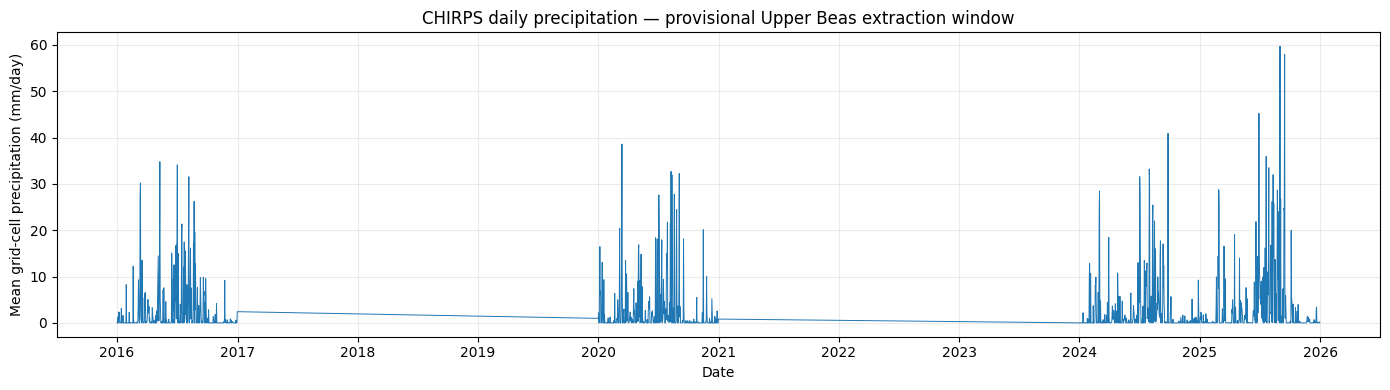

In [8]:
# 7. Quick exploratory plot: mean daily rainfall over extracted grid cells
daily_mean = (
    rain.groupby("time", as_index=False)["rainfall_daily_mm"]
        .mean()
        .sort_values("time")
)

plt.figure(figsize=(14, 4))
plt.plot(daily_mean["time"], daily_mean["rainfall_daily_mm"], linewidth=0.7)
plt.title("CHIRPS daily precipitation — provisional Upper Beas extraction window")
plt.xlabel("Date")
plt.ylabel("Mean grid-cell precipitation (mm/day)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. Save source and processing metadata

Record the source, access date, spatial window, period, units and caveats so the dataset is reproducible.


In [9]:
metadata = {
    "dataset_name": "CHIRPS v2.0 daily precipitation",
    "provider": "UCSB Climate Hazards Group; NOAA ERDDAP mirror",
    "dataset_id": "chirps20GlobalDailyP05",
    "source_url": "https://upwell.pfeg.noaa.gov/erddap/griddap/chirps20GlobalDailyP05.html",
    "variable": "precip",
    "units": "mm/day",
    "temporal_resolution": "daily",
    "nominal_spatial_resolution": "0.05 degrees",
    "start_date": START_DATE,
    "end_date": END_DATE,
    "provisional_bbox_wgs84": {
        "latitude_min": LAT_MIN, "latitude_max": LAT_MAX,
        "longitude_min": LON_MIN, "longitude_max": LON_MAX
    },
    "boundary_status": "Provisional bounding box only; not a delineated catchment polygon",
    "limitations": [
        "Daily precipitation cannot provide 1-hour or 3-hour rainfall intensity.",
        "CHIRPS grid values are estimates and should be validated against local gauges where possible.",
        "The extraction window must be clipped to a verified Upper Beas catchment boundary before final analysis."
    ]
}
metadata_path = DATA_RAW / "chirps_source_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved metadata:", metadata_path)


Saved metadata: C:\Users\AKRIT\Downloads\Flood\dataset\raw\chirps_source_metadata.json


## 9. Report notes — Dataset and study-area methodology

### 9.1 Study area
The project focuses on the Upper Beas Basin in Kullu district, Himachal Pradesh, India. The first extraction uses a provisional geographic bounding box solely to test data access and inspect coverage. A verified catchment boundary will be obtained or delineated before final spatial analysis.

### 9.2 Rainfall data
Daily precipitation is obtained from CHIRPS v2.0 through NOAA ERDDAP. The selected period is 1 January 2015 to 31 December 2025. The downloaded variable is `precip`, expressed in mm/day, on a nominal 0.05° grid. Three-day and seven-day rolling accumulations are derived per grid cell to represent antecedent rainfall conditions.

### 9.3 Limitations
Daily CHIRPS data do not resolve sub-daily rainfall bursts. Therefore, they cannot be interpreted as hourly rainfall intensity. NASA GPM IMERG half-hourly precipitation will be assessed as a complementary source for short-duration rainfall features. Gridded satellite products are estimates and should be compared with available gauge observations where possible.

### 9.4 Reproducibility
The raw NetCDF file, processed CSV, and JSON source metadata are retained separately. The processing script records the source URL, period, extraction window, units, and known limitations.


## 10. Next steps

1. Verify and obtain a real Upper Beas catchment boundary (not just the bounding rectangle).
2. Download NASA GPM IMERG Final half-hourly rainfall for 2015–2025; document Earthdata authentication and product version.
3. Acquire terrain elevation and derive slope from a documented DEM.
4. Derive drainage density and distance-to-stream from a consistent hydrography dataset.
5. Add soil moisture only after checking spatial/temporal resolution compatibility.
6. Obtain the HiFlo-DAT supplementary dataset and inspect its event-level fields; its published record covers 1846–2020, so it can validate only overlapping incidents within 2015–2020 unless newer verified records are added.
7. Build a time-aware, spatially consistent feature table. Do not fill unavailable values with invented measurements.

**Do not run DBSCAN yet.** First complete source acquisition, spatial clipping, temporal alignment, quality checks and feature engineering.
